# Baseline bird classifier

Trains a whole-image species classifier from`Training Manifest/bird_training_manifest.csv`
and exports it as TensorFlow Lite (float32 and full-integer int8)
This notebook is intended as a fixed reference for comparing preprocessing choices. Everything
that varies between experiments lives in the configuration cell; each run writes to its own folder
under `Models/runs/` and appends one row to `Models/experiments.csv`.

iNaturalist has no bbox, so the model sees the whole image for bothsources. The CUB `bbox` columns are ignored.
Source images are untouched
Pixel scaling is inside the model. The exported model takes raw RGB pixels in 0–255 (uint8 for the int8 model), so the only thing the Pi has to reproduce is the geometric step.
Splits come from `model_split` and labels from `class_index`. Nothing is re-split or
re-indexed here.

## 1. Configuration

In [1]:
import sys
import platform

print("Python:", sys.executable)
print("System:", platform.system())
print("Release:", platform.release())

Python: /home/joe/venvs/ESPclassifier/bin/python
System: Linux
Release: 6.6.87.2-microsoft-standard-WSL2


In [2]:
# ---- Experiment -------------------------------------------------------------
PREPROCESSING = "center_crop"   # "letterbox" | "stretch" | "center_crop"  (see section 3)
IMG_SIZE      = 224 # square model input, pixels
RUN_NAME      = None # default= "<preprocessing>_<size>_<timestamp>"
# ---- Model ------------------------------------------------------------------
BACKBONE_ALPHA = 1.0          # MobileNetV2 width: 0.35 / 0.5 / 0.75 / 1.0
WEIGHTS        = "imagenet"  
DROPOUT        = 0.2
# ---- Training ---------------------------------------------------------------
BATCH_SIZE        = 32
HEAD_EPOCHS       = 10  # backbone frozen
FINE_TUNE_EPOCHS  = 10 # 0 to skip fine-tuning
FINE_TUNE_LAYERS  = 40 # last N backbone layers unfrozen (BatchNorm stays frozen)
HEAD_LR           = 1e-3
FINE_TUNE_LR      = 1e-5
EARLY_STOP_PATIENCE = 4
AUGMENT_FLIP      = True
SEED              = 1234
# ---- Data location ----------------------------------------------------------
CUB_PHOTO_ROOT         =r"/mnt/e/Datasets/CUB_200/CUB_200_2011/images" #CUB200 contains notebooks, attributes.txt
INATURALIST_PHOTO_ROOT =r"/mnt/e/Datasets/iNaturalist/train_mini/train_mini" 
# ---- Quick checks -----------------------------------------------------------
LIMIT_PER_SPLIT   = None #200 for dry run None = everything
TFLITE_EVAL_LIMIT = None #cap images per split for the TFLite evaluation; None = all
REPRESENTATIVE_IMAGES = 300 #training images used to calibrate int8 quantisation

## 2. Load the manifest

In [3]:
import hashlib
import json
import os
import random
import shutil
import time
from datetime import datetime
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import tensorflow as tf

keras = tf.keras

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
tf.config.experimental.set_memory_growth(gpu, True) #using this instead of a hard VRAM limit(?), memory control will mostly haev to be done through batch_size

print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


_candidates = [Path.cwd(), Path.cwd() / "Models"]
MODELS_DIR = next((p for p in _candidates if (p / "Training Manifest").is_dir()), None)
if MODELS_DIR is None:
    raise FileNotFoundError(f"'Training Manifest' folder not found from {Path.cwd()}")
MANIFEST_DIR = MODELS_DIR / "Training Manifest"
MANIFEST_CSV = MANIFEST_DIR / "bird_training_manifest.csv"
CLASSES_CSV  = MANIFEST_DIR / "bird_training_classes.csv"
SUMMARY_JSON = MANIFEST_DIR / "bird_training_summary.json"


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


manifest_sha = sha256_file(MANIFEST_CSV)
classes_sha = sha256_file(CLASSES_CSV)
summary = json.loads(SUMMARY_JSON.read_text(encoding="utf-8"))
if manifest_sha != summary["outputs"]["training_manifest_sha256"]:
    raise ValueError("Manifest CSV does not match the hash in bird_training_summary.json; rebuild it.")
if classes_sha != summary["outputs"]["class_map_sha256"]:
    raise ValueError("Class map CSV does not match the hash in bird_training_summary.json; rebuild it.")

manifest = pd.read_csv(MANIFEST_CSV, encoding="utf-8", keep_default_na=False)
classes = pd.read_csv(CLASSES_CSV, encoding="utf-8", keep_default_na=False).sort_values("class_index")
NUM_CLASSES = len(classes)
CLASS_NAMES = classes["class_name"].tolist()
assert classes["class_index"].tolist() == list(range(NUM_CLASSES)), "class map is not contiguous"
assert manifest["class_index"].between(0, NUM_CLASSES - 1).all()
assert set(manifest["model_split"]) <= {"train", "validation", "test"}

print(f"{len(manifest):,} images, {NUM_CLASSES} classes")
manifest.groupby(["model_split", "source_dataset"]).size().unstack(fill_value=0)

I0000 00:00:1791571816.337128   20625 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791571816.382365   20625 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791571818.124284   20625 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
19,607 images, 179 classes


source_dataset,cub_200_2011,inaturalist
model_split,,
test,5293,895
train,4290,7160
validation,1074,895


In [4]:
# Resolve image paths
PHOTO_ROOTS = {"cub_200_2011": CUB_PHOTO_ROOT, "inaturalist": INATURALIST_PHOTO_ROOT}


def resolve_path(row):
    root = PHOTO_ROOTS.get(row.source_dataset)
    if not root:
        return row.image_path
    return str(Path(root).joinpath(*PurePosixPath(row.image_relative_path).parts[1:]))


manifest["path"] = [resolve_path(row) for row in manifest.itertuples(index=False)]

missing = [p for p in manifest["path"] if not os.path.isfile(p)]
if missing:
    raise FileNotFoundError(
        f"{len(missing):,} of {len(manifest):,} images not found. Mount the dataset drive or set "
        "CUB_PHOTO_ROOT / INATURALIST_PHOTO_ROOT in the configuration cell. First missing:\n  "
        + "\n  ".join(missing[:5])
    )

splits = {name: manifest[manifest["model_split"] == name].reset_index(drop=True)
          for name in ("train", "validation", "test")}
if LIMIT_PER_SPLIT:
    splits = {name: frame.sample(n=min(LIMIT_PER_SPLIT, len(frame)), random_state=SEED).reset_index(drop=True)
              for name, frame in splits.items()}
    print("LIMIT_PER_SPLIT is set: this is a dry run.")
{name: len(frame) for name, frame in splits.items()}

{'train': 11450, 'validation': 1969, 'test': 6188}

## 3. Preprocessing

Each function takes a decoded RGB image of any size (float32, 0–255) and returns IMG_SIZE × IMG_SIZE × 3 in the same 0–255 range. To try a new idea, add a function to
`PREPROCESSORS` and name it in `PREPROCESSING`.

| name | what it does | cost |
|---|---|---|
| `letterbox` | scale to fit, pad the rest with black | keeps the whole frame and its proportions; wastes input pixels on padding |
| `stretch` | resize straight to a square | keeps the whole frame; distorts shape (aspect ratios here run 0.4–3.6) |
| `center_crop` | scale the short side to size, crop the middle | no distortion or padding; loses the edges, and the bird is not always central |

A detector crop (e.g. YOLO boxes on iNaturalist) does not need to change this notebook: write the
cropped images to a new folder with the same relative paths and point `CUB_PHOTO_ROOT` /
`INATURALIST_PHOTO_ROOT` at it.

In [5]:
def letterbox(image, size):
    return tf.image.resize_with_pad(image, size, size, antialias=True)


def stretch(image, size):
    return tf.image.resize(image, [size, size], antialias=True)


def center_crop(image, size):
    shape = tf.cast(tf.shape(image)[:2], tf.float32)
    scale = tf.cast(size, tf.float32) / tf.reduce_min(shape)
    new_hw = tf.maximum(tf.cast(tf.math.ceil(shape * scale), tf.int32), size)
    image = tf.image.resize(image, new_hw, antialias=True)
    return tf.image.resize_with_crop_or_pad(image, size, size)


PREPROCESSORS = {"letterbox": letterbox, "stretch": stretch, "center_crop": center_crop}
preprocess_fn = PREPROCESSORS[PREPROCESSING]


def load_image(path):
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    image = preprocess_fn(tf.cast(image, tf.float32), IMG_SIZE)
    image = tf.clip_by_value(image, 0.0, 255.0)   # antialiased resizing can overshoot slightly
    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return image


def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].tolist(), frame["class_index"].astype("int32").tolist()))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda p, y: (load_image(p), y), num_parallel_calls=tf.data.AUTOTUNE)
    if training and AUGMENT_FLIP:
        ds = ds.map(lambda x, y: (tf.image.random_flip_left_right(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(splits["train"], training=True)
val_ds = make_dataset(splits["validation"])

I0000 00:00:1791571976.731800   20625 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3582 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


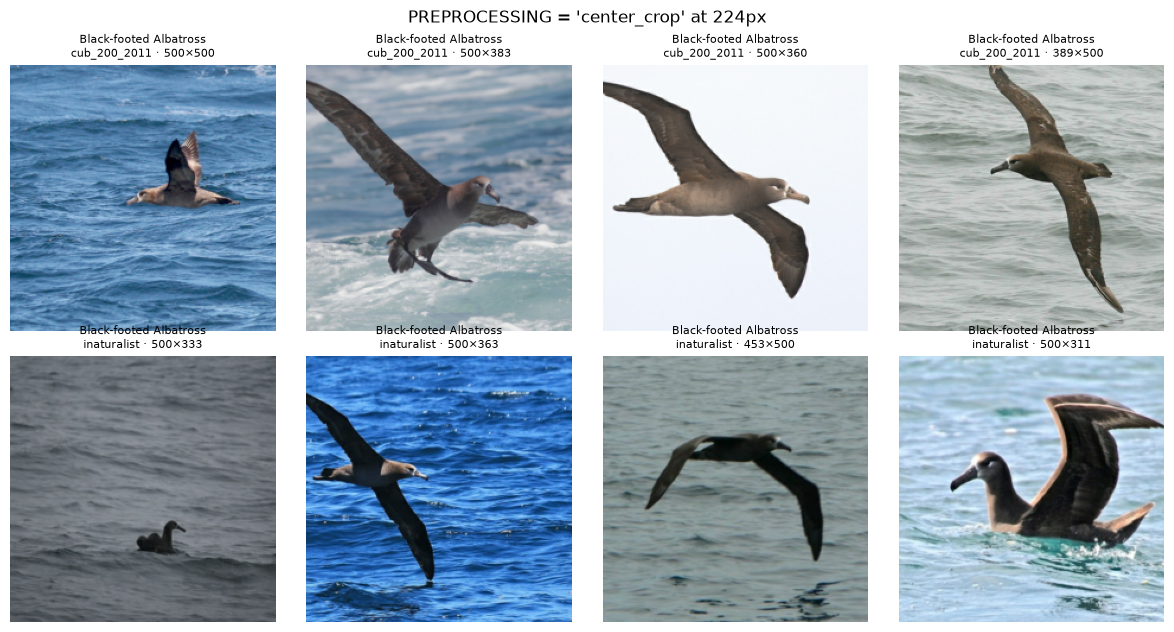

In [6]:
import matplotlib.pyplot as plt

preview = pd.concat([splits["train"][splits["train"]["source_dataset"] == s].head(4)
                     for s in ("cub_200_2011", "inaturalist")])
fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for ax, row in zip(axes.ravel(), preview.itertuples(index=False)):
    ax.imshow(load_image(row.path).numpy().astype("uint8"))
    ax.set_title(f"{row.class_name}\n{row.source_dataset} · {row.width_px}×{row.height_px}", fontsize=8)
    ax.axis("off")
fig.suptitle(f"PREPROCESSING = {PREPROCESSING!r} at {IMG_SIZE}px")
plt.tight_layout()
plt.show()

#YOLO on all un-bbox images will be needed 

## 4. Model
MobileNetV2 pretrained on ImageNet with a new 179-way (one for each bird species) softmax head. There are only ~64 training images per species, so a pretrained backbone is doing most of the work. Image augmentation would hopefully remedy it 

In [7]:
RUN_NAME = RUN_NAME or f"{PREPROCESSING}_{IMG_SIZE}_{datetime.now():%Y%m%d_%H%M%S}"
RUN_DIR = MODELS_DIR / "runs" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

backbone = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), alpha=BACKBONE_ALPHA, include_top=False, weights=WEIGHTS)
backbone.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
x = keras.layers.Rescaling(1.0 / 127.5, offset=-1.0, name="scale_to_minus1_1")(inputs)
x = backbone(x, training=False)            # BatchNorm stays in inference mode, also when fine-tuning
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(DROPOUT)(x)
outputs = keras.layers.Dense(NUM_CLASSES, activation="softmax", name="species")(x)
model = keras.Model(inputs, outputs, name="bird_baseline")


def compile_model(learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")],
    )


def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                          patience=EARLY_STOP_PATIENCE, restore_best_weights=True)]


print("Run folder:", RUN_DIR)
print(f"Parameters: {model.count_params():,}")

Run folder: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/center_crop_224_20261009_145301
Parameters: 2,487,283


## 5. Train

In [8]:
history = {}
started = time.time()

compile_model(HEAD_LR)
head = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, callbacks=callbacks())
for key, values in head.history.items():
    history.setdefault(key, []).extend(values)
head_epochs_run = len(head.history["loss"])

if FINE_TUNE_EPOCHS > 0:
    backbone.trainable = True
    for layer in backbone.layers[:-FINE_TUNE_LAYERS]:
        layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False
    compile_model(FINE_TUNE_LR)
    fine = model.fit(train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS, callbacks=callbacks())
    for key, values in fine.history.items():
        history.setdefault(key, []).extend(values)

train_minutes = (time.time() - started) / 60
print(f"Training took {train_minutes:.1f} min")

Epoch 1/10


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791571988.326165   20697 service.cc:153] XLA service 0x789f5415e670 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791571988.326246   20697 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3060 Laptop GPU, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791571988.533254   20697 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791571989.519347   20697 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1791571989.614890   20697 dot_merger.cc:4

357/358 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.2144 - loss: 3.6175 - top5: 0.4680

I0000 00:00:1791572030.991140   20697 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_8773__.123


358/358 ━━━━━━━━━━━━━━━━━━━━ 76s 159ms/step - accuracy: 0.2146 - loss: 3.6164 - top5: 0.4684 - val_accuracy: 0.3860 - val_loss: 2.5644 - val_top5: 0.7004
Epoch 2/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 31s 87ms/step - accuracy: 0.4699 - loss: 2.1698 - top5: 0.7657 - val_accuracy: 0.4505 - val_loss: 2.2763 - val_top5: 0.7430
Epoch 3/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 34s 94ms/step - accuracy: 0.5679 - loss: 1.7182 - top5: 0.8407 - val_accuracy: 0.4632 - val_loss: 2.1992 - val_top5: 0.7506
Epoch 4/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 33s 93ms/step - accuracy: 0.6286 - loss: 1.4489 - top5: 0.8818 - val_accuracy: 0.4860 - val_loss: 2.1482 - val_top5: 0.7618
Epoch 5/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 35s 98ms/step - accuracy: 0.6770 - loss: 1.2474 - top5: 0.9083 - val_accuracy: 0.4896 - val_loss: 2.1254 - val_top5: 0.7699
Epoch 6/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 32s 89ms/step - accuracy: 0.7154 - loss: 1.0965 - top5: 0.9282 - val_accuracy: 0.4810 - val_loss: 2.1555 - val_top5: 0.7699
Epoch 7/10
358/358 ━━━━━━━

I0000 00:00:1791572367.470772   20697 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_44655__.123


357/358 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.8566 - loss: 0.5456 - top5: 0.9796

I0000 00:00:1791572405.443707   20699 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_44655__.123


358/358 ━━━━━━━━━━━━━━━━━━━━ 68s 146ms/step - accuracy: 0.8563 - loss: 0.5461 - top5: 0.9795 - val_accuracy: 0.5135 - val_loss: 2.2082 - val_top5: 0.7791
Epoch 2/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 39s 109ms/step - accuracy: 0.8790 - loss: 0.4663 - top5: 0.9831 - val_accuracy: 0.5256 - val_loss: 2.1543 - val_top5: 0.7806
Epoch 3/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 29s 81ms/step - accuracy: 0.8928 - loss: 0.4120 - top5: 0.9867 - val_accuracy: 0.5251 - val_loss: 2.1590 - val_top5: 0.7862
Epoch 4/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 28s 77ms/step - accuracy: 0.9043 - loss: 0.3829 - top5: 0.9889 - val_accuracy: 0.5297 - val_loss: 2.1361 - val_top5: 0.7892
Epoch 5/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 25s 70ms/step - accuracy: 0.9145 - loss: 0.3443 - top5: 0.9914 - val_accuracy: 0.5287 - val_loss: 2.1917 - val_top5: 0.7862
Epoch 6/10
358/358 ━━━━━━━━━━━━━━━━━━━━ 25s 69ms/step - accuracy: 0.9246 - loss: 0.3110 - top5: 0.9934 - val_accuracy: 0.5175 - val_loss: 2.1859 - val_top5: 0.7887
Epoch 7/10
358/358 ━━━━━━

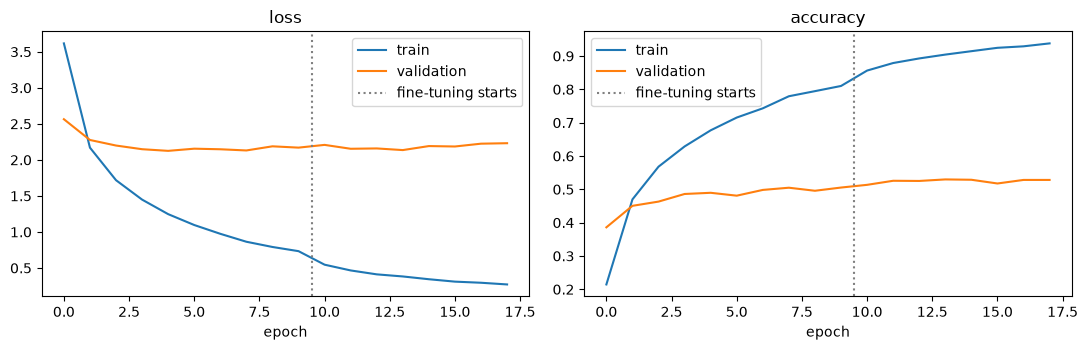

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric in zip(axes, ("loss", "accuracy")):
    ax.plot(history[metric], label="train")
    ax.plot(history["val_" + metric], label="validation")
    if FINE_TUNE_EPOCHS > 0:
        ax.axvline(head_epochs_run - 0.5, color="grey", linestyle=":", label="fine-tuning starts")
    ax.set_xlabel("epoch")
    ax.set_title(metric)
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Evaluate the Keras model

Reported per source as well as overall: the test split is ~86 % CUB (CUB's official test set is
kept whole), so the overall test number mostly reflects CUB. The iNaturalist rows are the closer
proxy for uncropped, in-the-wild photos. Although this is subject to change as I preprocess the images concretly, HAving physical pre-processed images made for OV2640 may be useful and cut preprocessing times between parameter experiementation, but will be useless with a bigger camera

In [10]:
def score(probabilities, frame):
    # Top-1 / top-5 accuracy overall and per source dataset.
    labels = frame["class_index"].to_numpy()[: len(probabilities)]
    sources = frame["source_dataset"].to_numpy()[: len(probabilities)]
    top5 = np.argsort(probabilities, axis=1)[:, -5:]
    hit1 = top5[:, -1] == labels
    hit5 = (top5 == labels[:, None]).any(axis=1)
    rows = []
    for name, mask in [("all", np.ones(len(labels), bool))] + [(s, sources == s) for s in sorted(set(sources))]:
        rows.append({"source": name, "images": int(mask.sum()),
                     "top1": float(hit1[mask].mean()), "top5": float(hit5[mask].mean())})
    return rows


results = []   # one row per (model, split, source)


def record(model_name, split_name, probabilities, extra=None):
    for row in score(probabilities, splits[split_name]):
        results.append({"model": model_name, "split": split_name, **row, **(extra or {})})


keras_probabilities = {}
for split_name in ("validation", "test"):
    keras_probabilities[split_name] = model.predict(make_dataset(splits[split_name]), verbose=0)
    record("keras", split_name, keras_probabilities[split_name])

pd.DataFrame(results).round(4)

I0000 00:00:1791572672.553485   24049 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_2', 84 bytes spill stores, 88 bytes spill loads



,model,split,source,images,top1,top5
0,keras,validation,all,1969,0.5297,0.7892
1,keras,validation,cub_200_2011,1074,0.6797,0.9097
2,keras,validation,inaturalist,895,0.3497,0.6447
3,keras,test,all,6188,0.6191,0.8636
4,keras,test,cub_200_2011,5293,0.6590,0.8985
5,keras,test,inaturalist,895,0.3832,0.6570


## 7. Export to TensorFlow Lite

Two files are written:

- `model_float32.tflite` — same weights as the Keras model; input float32 0–255.
- `model_int8.tflite` — full-integer quantisation, calibrated on training images; **uint8 in,
  uint8 out**. Roughly a quarter of the size and usually the faster one on a Pi's CPU.

In [11]:
keras_path = RUN_DIR / "model.keras"
model.save(keras_path)

saved_model_dir = RUN_DIR / "saved_model"
if hasattr(model, "export"):
    model.export(str(saved_model_dir))
    new_converter = lambda: tf.lite.TFLiteConverter.from_saved_model(str(saved_model_dir))
else:   # older tf.keras
    new_converter = lambda: tf.lite.TFLiteConverter.from_keras_model(model)

float_path = RUN_DIR / "model_float32.tflite"
float_path.write_bytes(new_converter().convert())

calibration = splits["train"].sample(n=min(REPRESENTATIVE_IMAGES, len(splits["train"])), random_state=SEED)


def representative_dataset():
    for path in calibration["path"]:
        yield [load_image(path)[tf.newaxis, ...]]


converter = new_converter()
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8
int8_path = RUN_DIR / "model_int8.tflite"
int8_path.write_bytes(converter.convert())

(RUN_DIR / "labels.txt").write_text("\n".join(CLASS_NAMES) + "\n", encoding="utf-8")
classes.to_csv(RUN_DIR / "bird_training_classes.csv", index=False)

shutil.rmtree(saved_model_dir, ignore_errors=True)   # only needed for conversion

for path in (float_path, int8_path):
    print(f"{path.name}: {path.stat().st_size / 1e6:.2f} MB")

INFO:tensorflow:Assets written to: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/center_crop_224_20261009_145301/saved_model/assets


INFO:tensorflow:Assets written to: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/center_crop_224_20261009_145301/saved_model/assets


Saved artifact at '/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/center_crop_224_20261009_145301/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 179), dtype=tf.float32, name=None)
Captures:
  132629998966096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132630270880912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132630270876688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132630270878992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132630270881296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132630270880528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132630270881680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132630270882448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132630270882064: TensorSpec(shape=(), dtype=tf.resource, name=N

W0000 00:00:1791572695.668789   20625 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1791572695.668862   20625 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1791572695.682068   20625 reader.cc:83] Reading SavedModel from: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/center_crop_224_20261009_145301/saved_model
I0000 00:00:1791572695.727927   20625 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1791572695.727988   20625 reader.cc:147] Reading SavedModel debug info (if present) from: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/center_crop_224_20261009_145301/saved_model
I0000 00:00:1791572695.834925   20625 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1791572695.855650   20625 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1791572697.353514   20625 loader.cc:220] Running initialization op on SavedModel bundle at pat

model_float32.tflite: 9.80 MB
model_int8.tflite: 2.97 MB


## 8. Evaluate the TFLite files

The exported files are run through the TFLite interpreter on the same images, so the numbers below
are for what will actually be deployed, including any accuracy lost to quantisation. Latency is
measured on this computer and only useful for comparing runs with each other, not as a Pi estimate.

In [12]:
try:
    from ai_edge_litert.interpreter import Interpreter   # the runtime the Pi will most likely use
except ImportError:
    Interpreter = tf.lite.Interpreter


def run_tflite(model_path, frame):
    # Returns float probabilities (n, classes) and mean milliseconds per image.
    interpreter = Interpreter(model_path=str(model_path), num_threads=os.cpu_count())
    interpreter.allocate_tensors()
    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]
    outputs, seconds = [], 0.0
    for path in frame["path"]:
        image = load_image(path).numpy()[None, ...]
        if inp["dtype"] != np.float32:
            scale, zero_point = inp["quantization"]
            limits = np.iinfo(inp["dtype"])
            image = np.clip(np.round(image / scale + zero_point), limits.min, limits.max)
        interpreter.set_tensor(inp["index"], image.astype(inp["dtype"]))
        tick = time.perf_counter()
        interpreter.invoke()
        seconds += time.perf_counter() - tick
        result = interpreter.get_tensor(out["index"])[0]
        if out["dtype"] != np.float32:
            scale, zero_point = out["quantization"]
            result = (result.astype(np.float32) - zero_point) * scale
        outputs.append(result)
    return np.stack(outputs), 1000 * seconds / len(frame)


tflite_info = {}
for model_name, path in (("tflite_float32", float_path), ("tflite_int8", int8_path)):
    tflite_info[model_name] = {"size_mb": path.stat().st_size / 1e6}
    for split_name in ("validation", "test"):
        frame = splits[split_name]
        if TFLITE_EVAL_LIMIT:
            frame = frame.head(TFLITE_EVAL_LIMIT)
        probabilities, ms = run_tflite(path, frame)
        record(model_name, split_name, probabilities)
        tflite_info[model_name]["ms_per_image"] = ms
        if split_name == "test":
            agree = (probabilities.argmax(1) == keras_probabilities["test"][: len(probabilities)].argmax(1)).mean()
            tflite_info[model_name]["test_agreement_with_keras"] = float(agree)
    print(model_name, {k: round(v, 3) for k, v in tflite_info[model_name].items()})

results_table = pd.DataFrame(results)
results_table.pivot_table(index=["model", "split"], columns="source", values="top1", sort=False).round(4)

/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


tflite_float32 {'size_mb': 9.804, 'ms_per_image': 2.968, 'test_agreement_with_keras': 0.999}
tflite_int8 {'size_mb': 2.966, 'ms_per_image': 2.58, 'test_agreement_with_keras': 0.852}


source                        all  cub_200_2011  inaturalist
model          split                                        
keras          validation  0.5297        0.6797       0.3497
               test        0.6191        0.6590       0.3832
tflite_float32 validation  0.5287        0.6797       0.3475
               test        0.6189        0.6590       0.3821
tflite_int8    validation  0.5114        0.6639       0.3285
               test        0.6008        0.6414       0.3609

## 9. Save the run and log it

`run_config.json` records everything needed to reproduce or deploy this model, including the
manifest and class-map hashes. `Models/experiments.csv` gets one row per run so preprocessing
variants can be compared side by side.

In [13]:
run_config = {
    "run_name": RUN_NAME,
    "created": datetime.now().isoformat(timespec="seconds"),
    "preprocessing": PREPROCESSING,
    "img_size": IMG_SIZE,
    "input": "RGB, 0-255, pixel scaling is inside the model",
    "backbone": f"MobileNetV2 alpha={BACKBONE_ALPHA} weights={WEIGHTS}",
    "dropout": DROPOUT,
    "batch_size": BATCH_SIZE,
    "head_epochs": HEAD_EPOCHS, "head_lr": HEAD_LR,
    "fine_tune_epochs": FINE_TUNE_EPOCHS, "fine_tune_layers": FINE_TUNE_LAYERS, "fine_tune_lr": FINE_TUNE_LR,
    "epochs_run": len(history["loss"]),
    "augment_flip": AUGMENT_FLIP,
    "seed": SEED,
    "limit_per_split": LIMIT_PER_SPLIT,
    "tflite_eval_limit": TFLITE_EVAL_LIMIT,
    "uses_bounding_boxes": False,
    "photo_roots": PHOTO_ROOTS,
    "num_classes": NUM_CLASSES,
    "images": {name: len(frame) for name, frame in splits.items()},
    "training_manifest_sha256": manifest_sha,
    "class_map_sha256": classes_sha,
    "tensorflow": tf.__version__,
    "train_minutes": round(train_minutes, 1),
    "tflite": tflite_info,
    "results": results,
}
(RUN_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2), encoding="utf-8")
results_table.to_csv(RUN_DIR / "results.csv", index=False)

# One wide row per run: <model>_<split>_<source>_top1 / _top5
log_row = {key: run_config[key] for key in
           ("run_name", "created", "preprocessing", "img_size", "backbone", "epochs_run",
            "limit_per_split", "tflite_eval_limit", "train_minutes", "training_manifest_sha256")}
for row in results:
    stem = f"{row['model']}_{row['split']}_{row['source']}"
    log_row[stem + "_top1"] = round(row["top1"], 4)
    log_row[stem + "_top5"] = round(row["top5"], 4)
for model_name, info in tflite_info.items():
    log_row[model_name + "_size_mb"] = round(info["size_mb"], 2)
    log_row[model_name + "_ms_per_image"] = round(info["ms_per_image"], 1)

log_path = MODELS_DIR / "experiments.csv"
log = pd.concat([pd.read_csv(log_path), pd.DataFrame([log_row])]) if log_path.exists() else pd.DataFrame([log_row])
log.to_csv(log_path, index=False)

print("Saved to", RUN_DIR)
log[["run_name", "preprocessing", "img_size",
     "tflite_int8_validation_all_top1", "tflite_int8_validation_inaturalist_top1",
     "tflite_int8_test_all_top1", "tflite_int8_test_inaturalist_top1"]].tail(10)

Saved to /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/center_crop_224_20261009_145301


,run_name,preprocessing,img_size,tflite_int8_validation_all_top1,tflite_int8_validation_inaturalist_top1,tflite_int8_test_all_top1,tflite_int8_test_inaturalist_top1
0,letterbox_224_20261009_125505,letterbox,224,0.0600,0.0421,0.0700,0.0345
1,letterbox_224_20261009_131631,letterbox,224,0.4469,0.2793,0.5368,0.2916
2,stretch_224_20261009_140350,stretch,224,0.4916,0.3028,0.5727,0.3408
0,center_crop_224_20261009_145301,center_crop,224,0.5114,0.3285,0.6008,0.3609


## Notes for comparing runs

- Compare preprocessing variants on **validation**; keep test for the final pick, otherwise the
  test set ends up being what you tuned against.
- Change one thing per run and keep `SEED` fixed. Differences of a point or so between two single
  runs are within run-to-run noise at this dataset size.
- On the Pi, the resize has to match the `PREPROCESSING` used here. A different library (e.g.
  Pillow) interpolates slightly differently from `tf.image.resize`, which can cost a little accuracy.
- This model only answers *which species*. Every training image contains a bird, so it cannot
  supply the `is_bird` decision the server's `classify()` expects; that needs feeder-camera
  negatives or a separate detector.